# Holt-Winters Additive and Multiplicative Forecasting

Holt-Winters (triple exponential smoothing) models **level, trend and seasonality**.

- **Additive seasonality:** seasonal changes are approximately constant in absolute units.
- **Multiplicative seasonality:** seasonal changes are proportional to the series level.

This notebook covers intuition, equations, worked examples, implementations from scratch, `statsmodels`, visualizations, chronological validation, parameter tuning, evaluation and future forecasts.

## Learning objectives
1. Distinguish additive and multiplicative seasonality.
2. Understand alpha, beta and gamma.
3. Implement both formulations from scratch.
4. Use `statsmodels` for model fitting.
5. Evaluate with a chronological train/validation/test split.

## 1. Setup

Install if required: `pip install numpy pandas matplotlib statsmodels scikit-learn`

In [1]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from sklearn.metrics import mean_absolute_error, mean_squared_error

np.random.seed(42)
plt.rcParams["figure.figsize"] = (12, 5)

## 2. Additive vs multiplicative seasonality

**Additive:** `Observed = Level + Trend + Seasonal effect + Error`. The seasonal component is measured in the same units as demand and is typically centred around zero.

**Multiplicative:** `Observed = (Level + Trend) × Seasonal factor × Error`. The seasonal component is a ratio/factor and is typically centred around one.

Example:
- Additive: December adds about 200 units whether baseline demand is 1,000 or 2,000.
- Multiplicative: December demand is about 1.2 times baseline, so the absolute uplift grows with baseline.

The standard multiplicative formulation requires strictly positive observations. If data contain zero or negative values, consider additive seasonality or a carefully justified transformation.

## 3. Create two synthetic monthly demand datasets

Both datasets contain 10 years of monthly observations. The additive series has roughly constant seasonal amplitude; the multiplicative series has seasonal factors applied to a growing level.

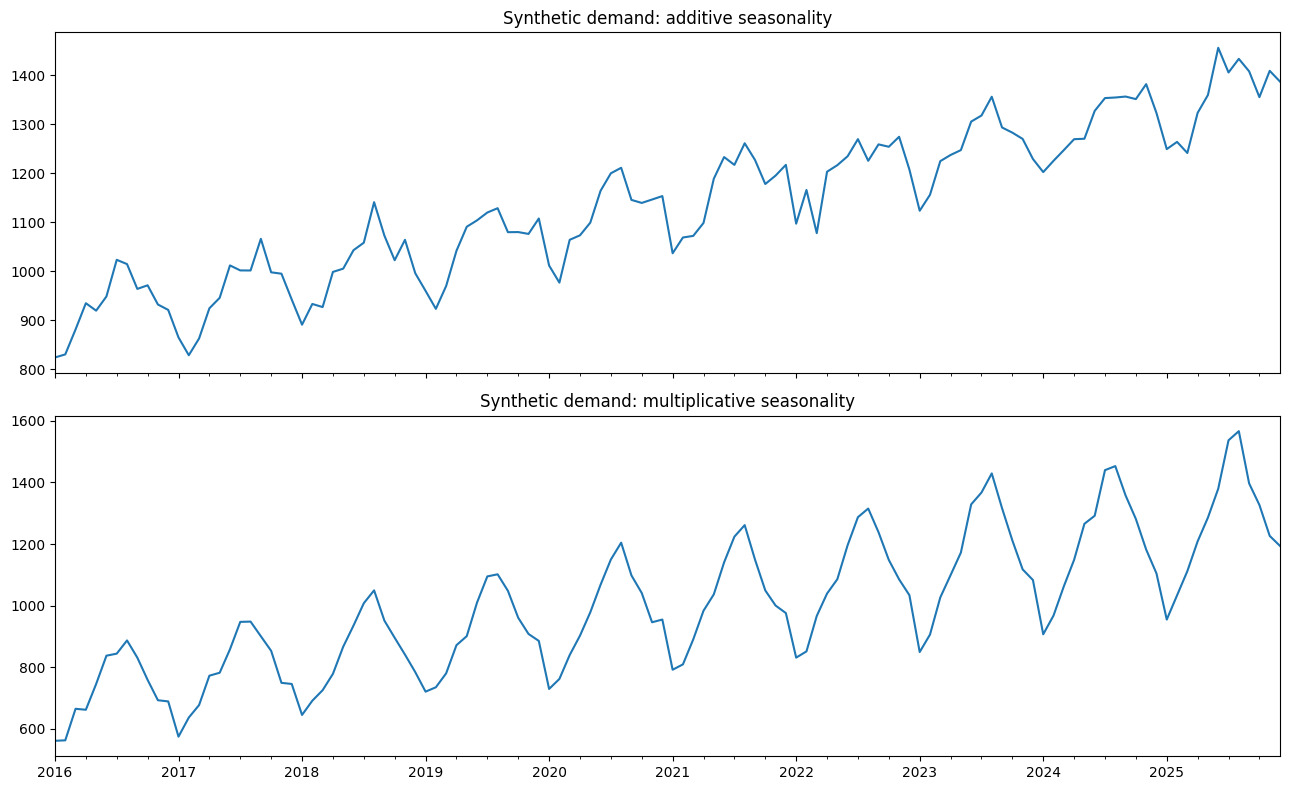

In [2]:
n, m = 120, 12
dates = pd.date_range("2016-01-01", periods=n, freq="MS")
t = np.arange(n)

add_pattern = np.array([-90,-70,-45,-20,10,35,55,65,45,20,5,-10], dtype=float)
add_values = 900 + 4*t + np.tile(add_pattern, n//m) + np.random.normal(0, 28, n)

mul_pattern = np.array([.78,.82,.90,.96,1.02,1.10,1.18,1.22,1.12,1.03,.96,.91])
mul_values = (700 + 5*t) * np.tile(mul_pattern, n//m) + np.random.normal(0, 18, n)
mul_values = np.maximum(mul_values, 1)

additive = pd.Series(add_values, index=dates, name="Additive demand")
multiplicative = pd.Series(mul_values, index=dates, name="Multiplicative demand")

fig, ax = plt.subplots(2, 1, figsize=(13, 8), sharex=True)
additive.plot(ax=ax[0], title="Synthetic demand: additive seasonality")
multiplicative.plot(ax=ax[1], title="Synthetic demand: multiplicative seasonality")
plt.tight_layout()
plt.show()

## 4. Holt-Winters equations

Notation:
- `Y_t`: actual observation
- `L_t`: estimated level
- `T_t`: estimated trend
- `S_t`: seasonal component
- `m`: observations per seasonal cycle
- `α`: level smoothing; `β`: trend smoothing; `γ`: seasonal smoothing
- `h`: forecast horizon

### Additive seasonality

Level:

$$L_t=\alpha(Y_t-S_{t-m})+(1-\alpha)(L_{t-1}+T_{t-1})$$

Trend:

$$T_t=\beta(L_t-L_{t-1})+(1-\beta)T_{t-1}$$

Seasonality:

$$S_t=\gamma(Y_t-L_t)+(1-\gamma)S_{t-m}$$

Forecast:

$$\hat Y_{t+h|t}=L_t+hT_t+S_{t-m+((h-1)\bmod m)+1}$$

### Multiplicative seasonality

Level:

$$L_t=\alpha\left(\frac{Y_t}{S_{t-m}}\right)+(1-\alpha)(L_{t-1}+T_{t-1})$$

Trend:

$$T_t=\beta(L_t-L_{t-1})+(1-\beta)T_{t-1}$$

Seasonality:

$$S_t=\gamma\left(\frac{Y_t}{L_t}\right)+(1-\gamma)S_{t-m}$$

Forecast:

$$\hat Y_{t+h|t}=(L_t+hT_t)\times S_{t-m+((h-1)\bmod m)+1}$$

These are standard formulations with additive trend. Damped-trend variants are also available.

## 5. Alpha, beta and gamma

| Parameter | Component | Effect |
|---|---|---|
| Alpha (α) | Level | Higher values make level respond more quickly to recent observations |
| Beta (β) | Trend | Higher values make trend adapt more quickly |
| Gamma (γ) | Seasonality | Higher values make seasonal factors adapt more quickly |

Lower values produce smoother component estimates. Parameters should be selected using a validation period or time-series cross-validation, not by inspecting test performance.

## 6. Worked additive update example

Assume previous level = 100, previous trend = 5, matching seasonal effect = 10, actual = 120, α = 0.4, β = 0.3 and γ = 0.2.

Level:

$$L_t=0.4(120-10)+0.6(100+5)=107$$

Trend:

$$T_t=0.3(107-100)+0.7(5)=5.6$$

Seasonal component:

$$S_t=0.2(120-107)+0.8(10)=10.6$$

The next forecast combines the updated level and trend with the seasonal effect for the relevant future month.

## 7. Initialization and from-scratch implementations

The functions below initialize seasonal components from the first two full cycles. This is a transparent educational initialization; other initialization methods can produce different estimates. Fitted values are recorded before updating with the current observation, so they are one-step-ahead fitted forecasts.

In [3]:
def initial_components(y, m, kind):
    y = np.asarray(y, dtype=float)
    if len(y) < 2*m:
        raise ValueError("At least two complete seasonal cycles are required.")
    a, b = y[:m], y[m:2*m]
    if kind == "add":
        seasonals = ((a-a.mean()) + (b-b.mean())) / 2
    else:
        if np.any(y <= 0):
            raise ValueError("Multiplicative seasonality requires positive observations.")
        seasonals = ((a/a.mean()) + (b/b.mean())) / 2
    level = (a.mean() + b.mean()) / 2
    trend = (b.mean() - a.mean()) / m
    return level, trend, list(seasonals)


def holt_winters_additive(y, m=12, alpha=.3, beta=.1, gamma=.1, horizon=0):
    y = np.asarray(y, dtype=float)
    if not (0 < alpha <= 1 and 0 <= beta <= 1 and 0 <= gamma <= 1):
        raise ValueError("Require alpha in (0,1], beta/gamma in [0,1].")
    level, trend, season = initial_components(y, m, "add")
    fitted = np.full(len(y), np.nan)
    for i in range(m, len(y)):
        j = i % m
        fitted[i] = level + trend + season[j]
        old_level = level
        level = alpha*(y[i]-season[j]) + (1-alpha)*(level+trend)
        trend = beta*(level-old_level) + (1-beta)*trend
        season[j] = gamma*(y[i]-level) + (1-gamma)*season[j]
    future = np.array([level+h*trend+season[(len(y)+h-1)%m]
                       for h in range(1, horizon+1)])
    return {"fitted": fitted, "level": level, "trend": trend,
            "seasonals": np.array(season), "forecast": future}


def holt_winters_multiplicative(y, m=12, alpha=.3, beta=.1, gamma=.1, horizon=0):
    y = np.asarray(y, dtype=float)
    if np.any(y <= 0):
        raise ValueError("Multiplicative Holt-Winters requires strictly positive data.")
    if not (0 < alpha <= 1 and 0 <= beta <= 1 and 0 <= gamma <= 1):
        raise ValueError("Require alpha in (0,1], beta/gamma in [0,1].")
    level, trend, season = initial_components(y, m, "mul")
    fitted = np.full(len(y), np.nan)
    for i in range(m, len(y)):
        j = i % m
        fitted[i] = (level + trend) * season[j]
        old_level = level
        level = alpha*(y[i]/season[j]) + (1-alpha)*(level+trend)
        trend = beta*(level-old_level) + (1-beta)*trend
        season[j] = gamma*(y[i]/level) + (1-gamma)*season[j]
    future = np.array([(level+h*trend)*season[(len(y)+h-1)%m]
                       for h in range(1, horizon+1)])
    return {"fitted": fitted, "level": level, "trend": trend,
            "seasonals": np.array(season), "forecast": future}

## 8. Fit manual models and inspect fitted values

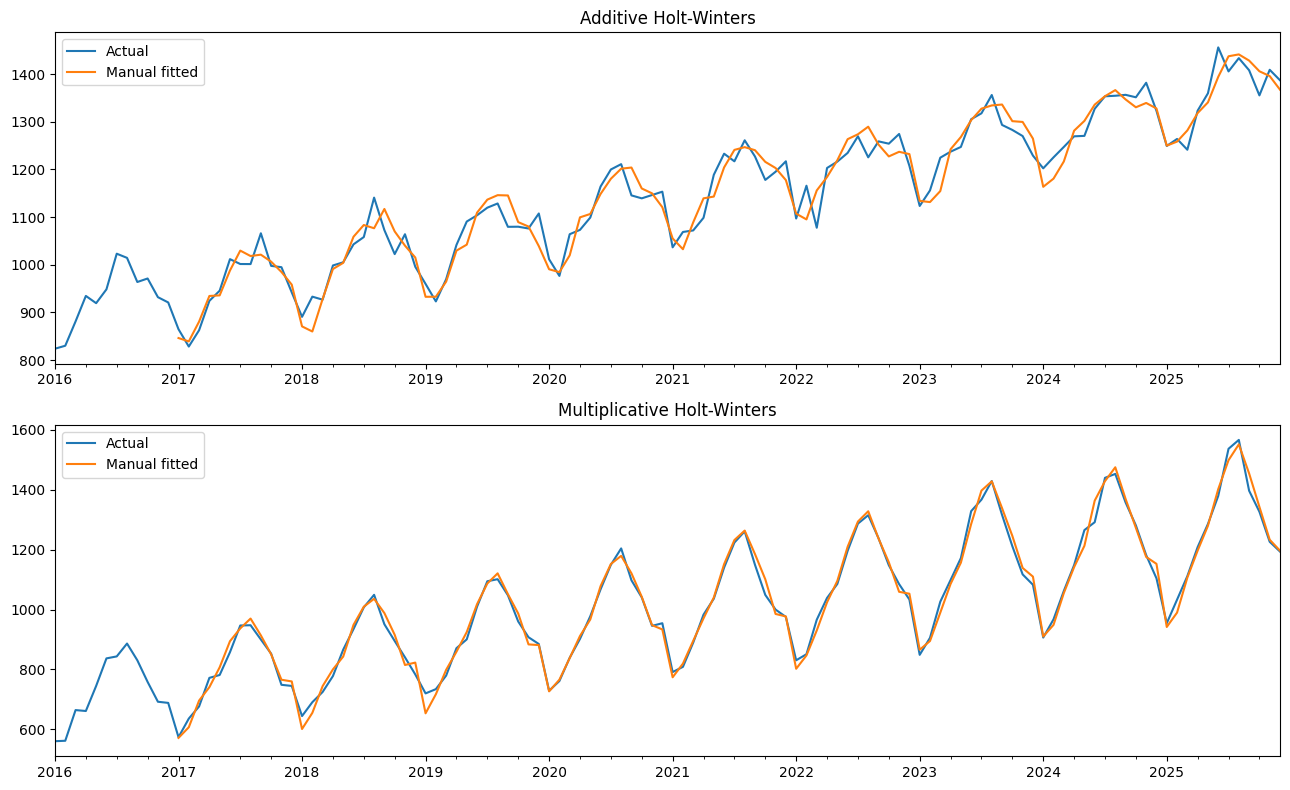

In [4]:
add_manual = holt_winters_additive(additive.values, m, .3, .1, .2, 12)
mul_manual = holt_winters_multiplicative(multiplicative.values, m, .3, .1, .2, 12)

fig, ax = plt.subplots(2, 1, figsize=(13, 8))
additive.plot(ax=ax[0], label="Actual")
pd.Series(add_manual["fitted"], index=dates).plot(ax=ax[0], label="Manual fitted")
ax[0].set_title("Additive Holt-Winters")
ax[0].legend()
multiplicative.plot(ax=ax[1], label="Actual")
pd.Series(mul_manual["fitted"], index=dates).plot(ax=ax[1], label="Manual fitted")
ax[1].set_title("Multiplicative Holt-Winters")
ax[1].legend()
plt.tight_layout()
plt.show()

## 9. Inspect seasonal components

Additive seasonal effects are in demand units and typically centred near zero. Multiplicative seasonal factors are ratios and typically centred near one.

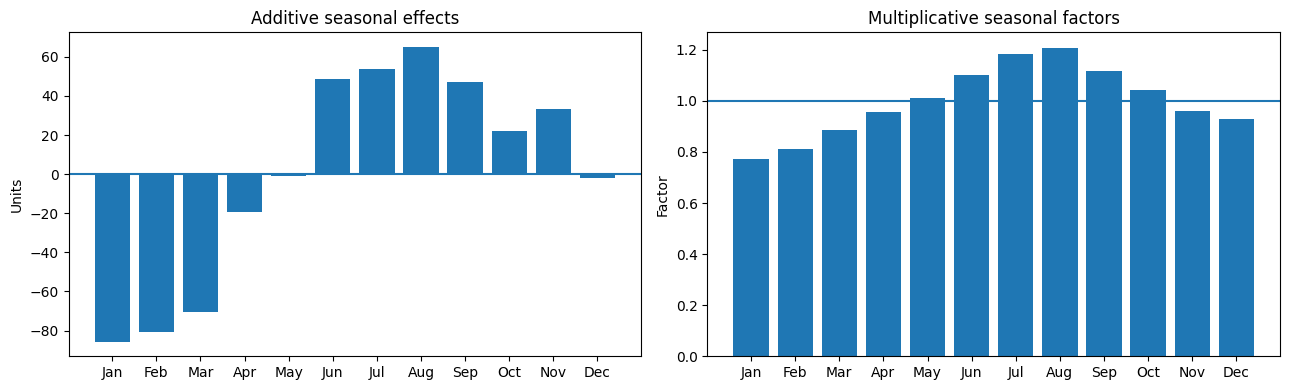

In [5]:
months = ["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"]
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].bar(months, add_manual["seasonals"]); ax[0].axhline(0)
ax[0].set_title("Additive seasonal effects"); ax[0].set_ylabel("Units")
ax[1].bar(months, mul_manual["seasonals"]); ax[1].axhline(1)
ax[1].set_title("Multiplicative seasonal factors"); ax[1].set_ylabel("Factor")
plt.tight_layout(); plt.show()

## 10. Chronological train-validation-test split

We use 70% training, 15% validation and 15% test. The validation set selects parameters; the test set is reserved for final evaluation. Never randomly shuffle ordinary time-series data.

In [6]:
def split_series(s):
    n = len(s)
    a, b = int(.70*n), int(.85*n)
    return s.iloc[:a], s.iloc[a:b], s.iloc[b:]

a_train, a_val, a_test = split_series(additive)
m_train, m_val, m_test = split_series(multiplicative)
print("Additive lengths:", len(a_train), len(a_val), len(a_test))
print("Multiplicative lengths:", len(m_train), len(m_val), len(m_test))

Additive lengths: 84 18 18
Multiplicative lengths: 84 18 18


## 11. Evaluation metrics

- **MAE:** average absolute error, in demand units.
- **RMSE:** penalizes large errors more heavily.
- **WMAPE:** total absolute error divided by total absolute actual demand.
- **Mean bias:** mean forecast minus actual; positive means overforecasting.

MAPE is not used as the primary metric because it is undefined or unstable when actual values are zero or close to zero.

In [7]:
def metrics(actual, pred):
    actual, pred = np.asarray(actual), np.asarray(pred)
    return {
        "MAE": mean_absolute_error(actual, pred),
        "RMSE": np.sqrt(mean_squared_error(actual, pred)),
        "WMAPE": np.sum(np.abs(actual-pred))/np.sum(np.abs(actual)),
        "Mean Bias": np.mean(pred-actual)
    }

def manual_forecast(func, train, h, params):
    return func(train.values, m=12, horizon=h, **params)["forecast"]

def tune(func, train, valid):
    rows = []
    for alpha in [.2, .4, .6]:
        for beta in [.05, .15, .30]:
            for gamma in [.05, .20, .40]:
                p = {"alpha":alpha, "beta":beta, "gamma":gamma}
                pred = manual_forecast(func, train, len(valid), p)
                rows.append({**p, **metrics(valid.values, pred)})
    table = pd.DataFrame(rows).sort_values("WMAPE").reset_index(drop=True)
    best = table.iloc[0][["alpha","beta","gamma"]].to_dict()
    return table, best

a_tuning, a_best = tune(holt_winters_additive, a_train, a_val)
m_tuning, m_best = tune(holt_winters_multiplicative, m_train, m_val)
print("Best additive parameters:", a_best)
display(a_tuning.head())
print("Best multiplicative parameters:", m_best)
display(m_tuning.head())

Best additive parameters: {'alpha': 0.2, 'beta': 0.05, 'gamma': 0.2}


,alpha,beta,gamma,MAE,RMSE,WMAPE,Mean Bias
0,0.2,0.05,0.20,21.896903,27.933523,0.017452,-8.690209
1,0.2,0.05,0.40,22.393782,29.925858,0.017848,-8.122037
2,0.2,0.05,0.05,23.060929,28.957937,0.018380,-10.716546
3,0.6,0.05,0.05,23.703365,29.850965,0.018892,-10.223177
4,0.6,0.15,0.05,24.011068,29.717583,0.019137,-9.051167


Best multiplicative parameters: {'alpha': 0.2, 'beta': 0.15, 'gamma': 0.4}


,alpha,beta,gamma,MAE,RMSE,WMAPE,Mean Bias
0,0.2,0.15,0.4,19.794149,26.069055,0.017339,0.240440
1,0.2,0.05,0.4,19.875709,26.441518,0.017411,-5.939083
2,0.2,0.30,0.2,19.976620,26.026014,0.017499,-5.101947
3,0.2,0.15,0.2,20.708312,26.833445,0.018140,-8.986457
4,0.2,0.05,0.2,21.345454,27.582906,0.018698,-11.533669


## 12. Evaluate on the untouched test set

Refit on training plus validation history, then forecast the test horizon.

,MAE,RMSE,WMAPE,Mean Bias
Model,,,,
Manual additive,23.115075,28.864164,0.017044,-16.670219
Manual multiplicative,21.761293,26.965271,0.017000,-16.679761


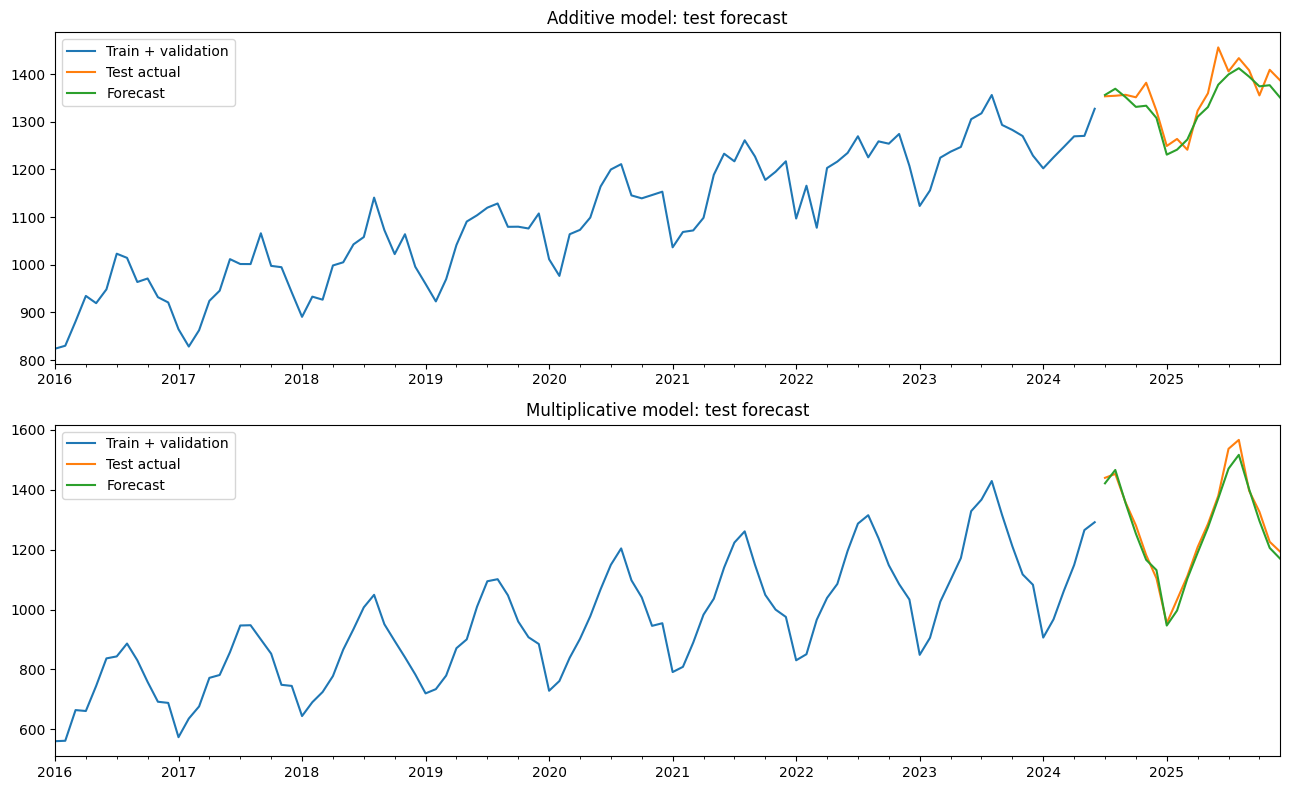

In [8]:
a_trainval = pd.concat([a_train, a_val])
m_trainval = pd.concat([m_train, m_val])

a_pred = manual_forecast(holt_winters_additive, a_trainval, len(a_test), a_best)
m_pred = manual_forecast(holt_winters_multiplicative, m_trainval, len(m_test), m_best)

display(pd.DataFrame([
    {"Model":"Manual additive", **metrics(a_test.values, a_pred)},
    {"Model":"Manual multiplicative", **metrics(m_test.values, m_pred)}
]).set_index("Model"))

fig, ax = plt.subplots(2, 1, figsize=(13, 8))
a_trainval.plot(ax=ax[0], label="Train + validation")
a_test.plot(ax=ax[0], label="Test actual")
pd.Series(a_pred, index=a_test.index).plot(ax=ax[0], label="Forecast")
ax[0].set_title("Additive model: test forecast"); ax[0].legend()
m_trainval.plot(ax=ax[1], label="Train + validation")
m_test.plot(ax=ax[1], label="Test actual")
pd.Series(m_pred, index=m_test.index).plot(ax=ax[1], label="Forecast")
ax[1].set_title("Multiplicative model: test forecast"); ax[1].legend()
plt.tight_layout(); plt.show()

## 13. Fit with statsmodels

`statsmodels` estimates initial states and smoothing parameters through its fitting procedure. Results may differ from the manual implementation because initialization and optimization differ.

- `trend="add"` specifies additive trend.
- `seasonal="add"` or `"mul"` specifies seasonal form.
- `seasonal_periods=12` represents annual seasonality in monthly data.
- `optimized=True` estimates parameters from the training data.

In [9]:
def fit_hw(train, seasonal):
    model = ExponentialSmoothing(
        train, trend="add", seasonal=seasonal,
        seasonal_periods=12, initialization_method="estimated"
    )
    return model.fit(optimized=True)

a_sm = fit_hw(a_trainval, "add")
m_sm = fit_hw(m_trainval, "mul")
a_sm_pred = a_sm.forecast(len(a_test))
m_sm_pred = m_sm.forecast(len(m_test))

display(pd.DataFrame([
    {"Model":"Statsmodels additive", **metrics(a_test.values, a_sm_pred.values)},
    {"Model":"Statsmodels multiplicative", **metrics(m_test.values, m_sm_pred.values)}
]).set_index("Model"))
print("Additive fitted parameters:", a_sm.params)
print("Multiplicative fitted parameters:", m_sm.params)

,MAE,RMSE,WMAPE,Mean Bias
Model,,,,
Statsmodels additive,19.088935,24.987148,0.014075,-5.994650
Statsmodels multiplicative,15.907949,20.551712,0.012427,8.415389


Additive fitted parameters: {'smoothing_level': np.float64(1.4901161193847656e-08), 'smoothing_trend': np.float64(0.0), 'smoothing_seasonal': np.float64(0.0), 'damping_trend': nan, 'initial_level': np.float64(895.1044018145715), 'initial_trend': np.float64(4.009885373344358), 'initial_seasons': array([-90.4570807 , -83.67981207, -63.39031031, -16.92043272,
         1.55402212,  40.70363298,  59.26222007,  71.77974688,
        38.76427597,  12.03786412,  11.48387933, -14.95909639]), 'use_boxcox': False, 'lamda': None, 'remove_bias': False}
Multiplicative fitted parameters: {'smoothing_level': np.float64(1.4901161193847656e-08), 'smoothing_trend': np.float64(7.234489753253127e-10), 'smoothing_seasonal': np.float64(0.0), 'damping_trend': nan, 'initial_level': np.float64(721.0745675481853), 'initial_trend': np.float64(5.272827371336026), 'initial_seasons': array([0.74784383, 0.77944882, 0.85605497, 0.92189291, 0.98139594,
       1.06646826, 1.13856364, 1.16800539, 1.07728304, 0.99385691,
 

## 14. Compare manual and statsmodels results

In [10]:
display(pd.DataFrame([
    {"Model":"Manual additive", **metrics(a_test.values, a_pred)},
    {"Model":"Statsmodels additive", **metrics(a_test.values, a_sm_pred.values)},
    {"Model":"Manual multiplicative", **metrics(m_test.values, m_pred)},
    {"Model":"Statsmodels multiplicative", **metrics(m_test.values, m_sm_pred.values)}
]).set_index("Model"))

,MAE,RMSE,WMAPE,Mean Bias
Model,,,,
Manual additive,23.115075,28.864164,0.017044,-16.670219
Statsmodels additive,19.088935,24.987148,0.014075,-5.994650
Manual multiplicative,21.761293,26.965271,0.017000,-16.679761
Statsmodels multiplicative,15.907949,20.551712,0.012427,8.415389


## 15. Refit on all observations and forecast the next 12 months

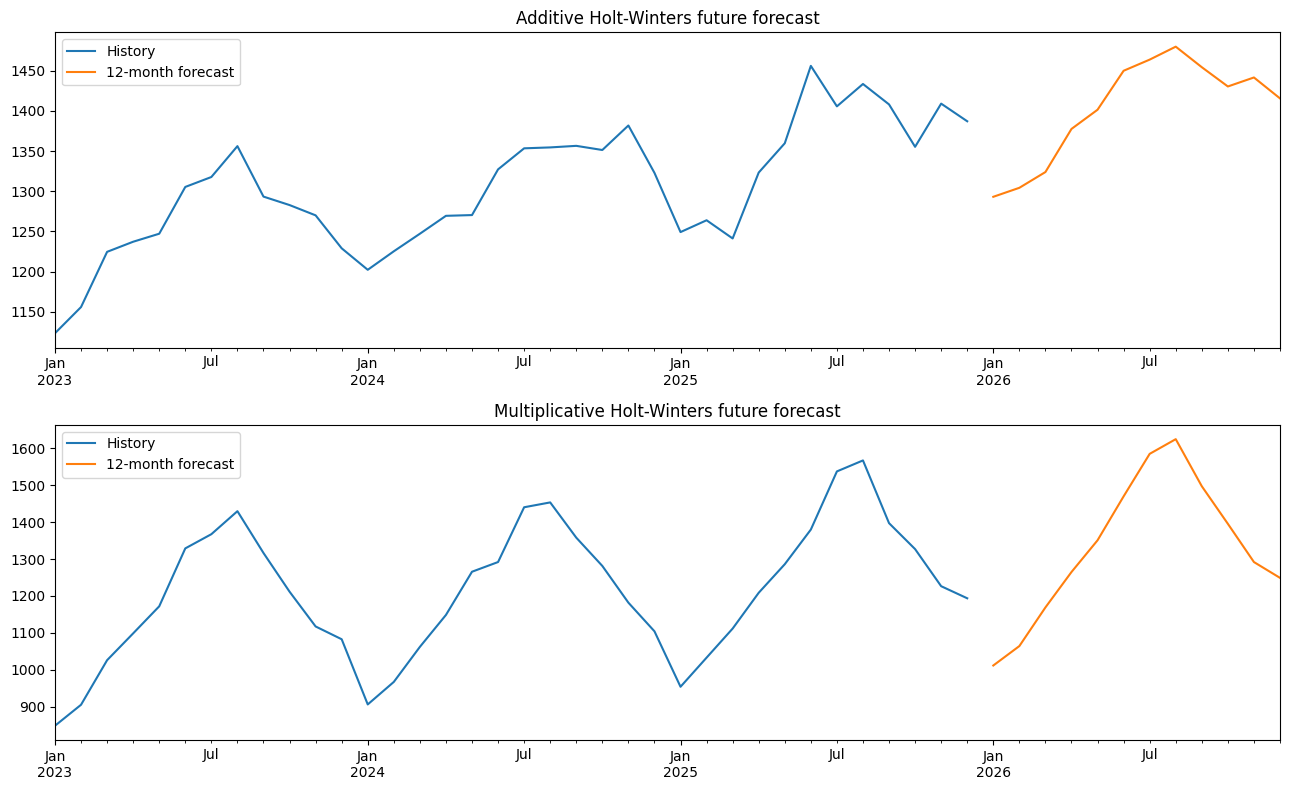

,Additive forecast,Multiplicative forecast
2026-01-01,1293.101784,1011.876310
2026-02-01,1304.287301,1064.461300
2026-03-01,1323.887451,1169.061274
2026-04-01,1377.522331,1264.909002
2026-05-01,1401.405909,1350.768743
2026-06-01,1449.882451,1469.675844
2026-07-01,1463.752037,1584.716281
2026-08-01,1479.865879,1624.471486
2026-09-01,1454.310628,1497.052430
2026-10-01,1430.345253,1395.365845


In [11]:
a_final = fit_hw(additive, "add")
m_final = fit_hw(multiplicative, "mul")
a_future = a_final.forecast(12)
m_future = m_final.forecast(12)

fig, ax = plt.subplots(2, 1, figsize=(13, 8))
additive.iloc[-36:].plot(ax=ax[0], label="History")
a_future.plot(ax=ax[0], label="12-month forecast")
ax[0].set_title("Additive Holt-Winters future forecast"); ax[0].legend()
multiplicative.iloc[-36:].plot(ax=ax[1], label="History")
m_future.plot(ax=ax[1], label="12-month forecast")
ax[1].set_title("Multiplicative Holt-Winters future forecast"); ax[1].legend()
plt.tight_layout(); plt.show()

display(pd.DataFrame({"Additive forecast":a_future,
                      "Multiplicative forecast":m_future}))

## 16. Damped vs undamped trend

An undamped linear trend continues at the same rate for every future period. This can produce unrealistic long-range forecasts. A damped trend gradually reduces the trend contribution.

`statsmodels` supports `damped_trend=True`.

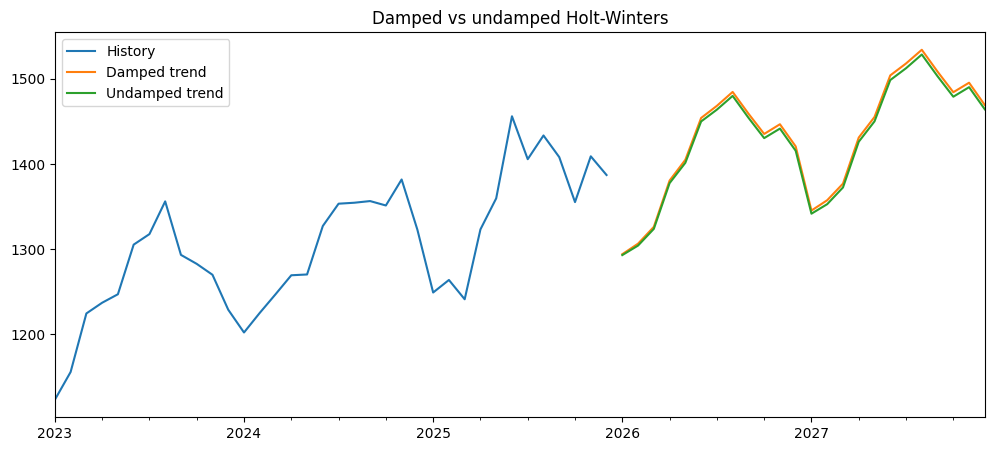

In [12]:
damped = ExponentialSmoothing(
    additive, trend="add", damped_trend=True,
    seasonal="add", seasonal_periods=12,
    initialization_method="estimated"
).fit(optimized=True)
undamped = ExponentialSmoothing(
    additive, trend="add", damped_trend=False,
    seasonal="add", seasonal_periods=12,
    initialization_method="estimated"
).fit(optimized=True)

additive.iloc[-36:].plot(label="History")
damped.forecast(24).plot(label="Damped trend")
undamped.forecast(24).plot(label="Undamped trend")
plt.title("Damped vs undamped Holt-Winters")
plt.legend(); plt.show()

## 17. Residual analysis

Residuals are actual minus fitted values. Look for remaining trend, seasonality, autocorrelation, outliers or changing variance. A good in-sample fit does not guarantee future accuracy.

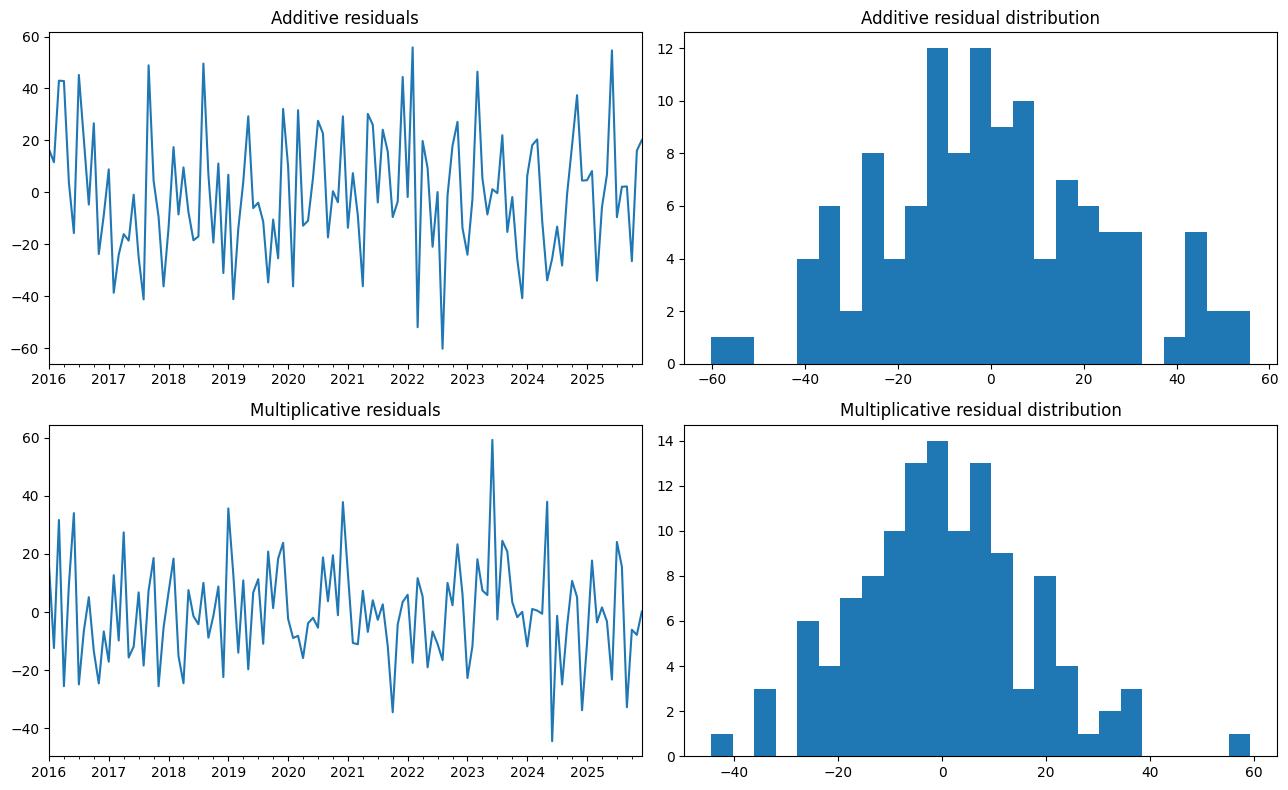

In [13]:
a_resid = additive - a_final.fittedvalues
m_resid = multiplicative - m_final.fittedvalues

fig, ax = plt.subplots(2, 2, figsize=(13, 8))
a_resid.plot(ax=ax[0,0], title="Additive residuals")
ax[0,1].hist(a_resid.dropna(), bins=25); ax[0,1].set_title("Additive residual distribution")
m_resid.plot(ax=ax[1,0], title="Multiplicative residuals")
ax[1,1].hist(m_resid.dropna(), bins=25); ax[1,1].set_title("Multiplicative residual distribution")
plt.tight_layout(); plt.show()

## 18. Supply-chain applications

**Additive candidate:** a product receives roughly the same extra unit demand each festive season, even as its baseline changes.

**Multiplicative candidate:** demand rises by a relatively stable percentage during a seasonal period, so absolute seasonal peaks become larger as baseline demand grows.

Potential use cases include retail, apparel, food and beverage, consumer products and location-level demand with stable recurring seasonality.

Holt-Winters does not directly model promotions, price changes, stockouts, holidays or causal drivers. Those may require event adjustments, regression, SARIMAX or machine-learning approaches.

## 19. Advantages and limitations

### Advantages
- Models level, trend and seasonality together.
- Interpretable and computationally efficient.
- Useful statistical benchmark for recurring seasonal demand.
- Two seasonal forms cover different amplitude behaviours.

### Limitations
- Requires a meaningful seasonal frequency and enough history.
- Multiplicative form requires positive observations.
- May struggle with changing or irregular seasonal patterns.
- Does not automatically incorporate external drivers.
- Undamped trend can become unrealistic at long horizons.
- Usually not the first choice for highly intermittent demand.

## 20. Common mistakes
1. Choosing an incorrect seasonal period.
2. Using multiplicative seasonality with zeros or negatives.
3. Randomly splitting time-series data.
4. Tuning parameters on the test set.
5. Using too little history; at least two complete cycles are useful for initialization.
6. Assuming seasonality is stable without checking it.
7. Ignoring long-horizon trend uncertainty.
8. Ignoring stockouts, promotions and structural breaks.

## 21. Practice exercises
1. Change the seasonal period to 4 and simulate quarterly data.
2. Increase additive seasonal amplitude and inspect seasonal estimates.
3. Change multiplicative factors and compare forecasts.
4. Compare damped and undamped forecasts at 24 and 36 months.
5. Add a structural break and measure model adaptation.
6. Compare both seasonal forms on the same positive series using validation data.
7. Test the multiplicative function with zero demand.
8. Implement rolling-origin evaluation.

## 22. Key takeaways
- Holt-Winters is triple exponential smoothing: level + trend + seasonality.
- Additive seasonality fits roughly constant absolute seasonal effects.
- Multiplicative seasonality fits seasonal effects proportional to the level.
- Alpha, beta and gamma update level, trend and seasonality.
- Use chronological validation and an untouched test set.
- Select based on data behaviour, forecast accuracy, bias and business context.

## References
- [Statsmodels: ExponentialSmoothing](https://www.statsmodels.org/stable/generated/statsmodels.tsa.holtwinters.ExponentialSmoothing.html)
- [Forecasting: Principles and Practice — Exponential Smoothing](https://otexts.com/fpp3/expsmooth.html)
- [Forecasting: Principles and Practice — Holt-Winters' Seasonal Method](https://otexts.com/fpp3/holt-winters.html)